# **Preparing Dependencies**

Instalasi library yang dibutuhkan:
- `diffusers` — library utama untuk Stable Diffusion Pipeline
- `transformers` — diperlukan oleh diffusers untuk tokenizer & text encoder
- `accelerate` — mempercepat loading model ke GPU
- `torch` — framework deep learning (PyTorch)
- `Pillow` — manipulasi gambar (PIL)
- `matplotlib` — visualisasi gambar di notebook

In [1]:
!pip install -q --upgrade diffusers transformers accelerate huggingface_hub
!pip install -q xformers Pillow matplotlib

import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from diffusers import (
    StableDiffusionPipeline,
    StableDiffusionInpaintPipeline,
    StableDiffusionImg2ImgPipeline,
    EulerAncestralDiscreteScheduler,
    DPMSolverMultistepScheduler,
    DDIMScheduler
)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 120.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 642.6/642.6 kB 51.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 129.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 116.1 MB/s eta 0:00:00


Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Device: cuda
GPU: Tesla T4


# **Kriteria 1: Melakukan Image Generation dari Teks (Text-to-Image)**

## **Load Base Pipeline Model**

Model `runwayml/stable-diffusion-v1-5` di-load menggunakan `StableDiffusionPipeline`.
- `torch_dtype=torch.float16` → menghemat VRAM GPU (half precision)
- `.to(DEVICE)` → memindahkan model ke GPU
- `enable_attention_slicing()` → optimasi memori agar tidak OOM di GPU free tier

In [2]:
MODEL_ID = "runwayml/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    safety_checker=None,      # nonaktifkan safety checker agar lebih cepat
    requires_safety_checker=False
).to(DEVICE)

pipe.enable_attention_slicing()  # hemat VRAM

print("Model berhasil di-load!")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model berhasil di-load!


## **Generate Image**

### Fungsi `generate_simple_image()`
Fungsi standar text-to-image menggunakan parameter dasar:
- `prompt` — deskripsi gambar yang ingin dihasilkan
- `negative_prompt` — hal-hal yang TIDAK ingin muncul di gambar
- `seed` — angka untuk membuat hasil reproducible (deterministic)

**Prompt yang digunakan** ditujukan untuk mereproduksi gambar astronot berdiri di permukaan Mars dengan Bumi terlihat di latar langit.

  0%|          | 0/50 [00:00<?, ?it/s]

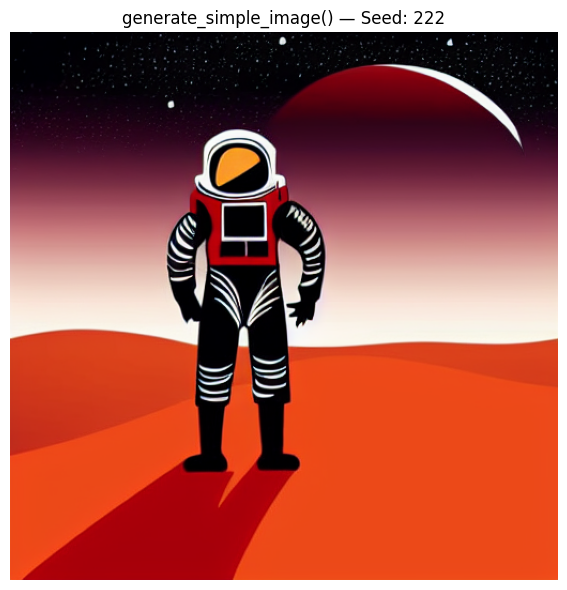

In [23]:
# Prompt & parameter yang digunakan pada kedua fungsi (sama agar bisa dibandingkan)
PROMPT = (
    "an astronaut standing on the surface of Mars, "
    "Earth visible in the dark sky background, "
    "red dusty ground, digital art, illustration, "
    "cartoon style, clean lines, vivid colors"
    )

NEGATIVE_PROMPT = (
    "photorealistic, realistic, photograph, 3d render, "
    "messy, blurry, low quality, bad art, ugly, sketch, "
    "grainy, unfinished, chromatic aberration"
)

SEED = 222


def generate_simple_image(prompt, negative_prompt, seed):

    generator = torch.Generator(device=DEVICE).manual_seed(seed)

    result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        generator=generator
    )

    return result.images[0]


# Jalankan generate_simple_image
simple_image = generate_simple_image(PROMPT, NEGATIVE_PROMPT, SEED)

plt.figure(figsize=(6, 6))
plt.imshow(simple_image)
plt.title("generate_simple_image() — Seed: 222")
plt.axis("off")
plt.tight_layout()
plt.show()

## **Generate Image with Hyperparameter Configuration**

### Fungsi `generate_advanced_image()`
Fungsi lanjutan yang menambahkan dua parameter penting:
- `guidance_scale` (CFG Scale) — mengontrol seberapa kuat model mengikuti prompt. Nilai tinggi → gambar lebih sesuai prompt tapi kurang kreatif.
- `num_inference_steps` — jumlah langkah denoising. Lebih banyak step → gambar lebih detail & halus, tapi lebih lambat.

**Prompt yang digunakan sama** dengan `generate_simple_image()` agar bisa dibandingkan secara objektif.

  0%|          | 0/40 [00:00<?, ?it/s]

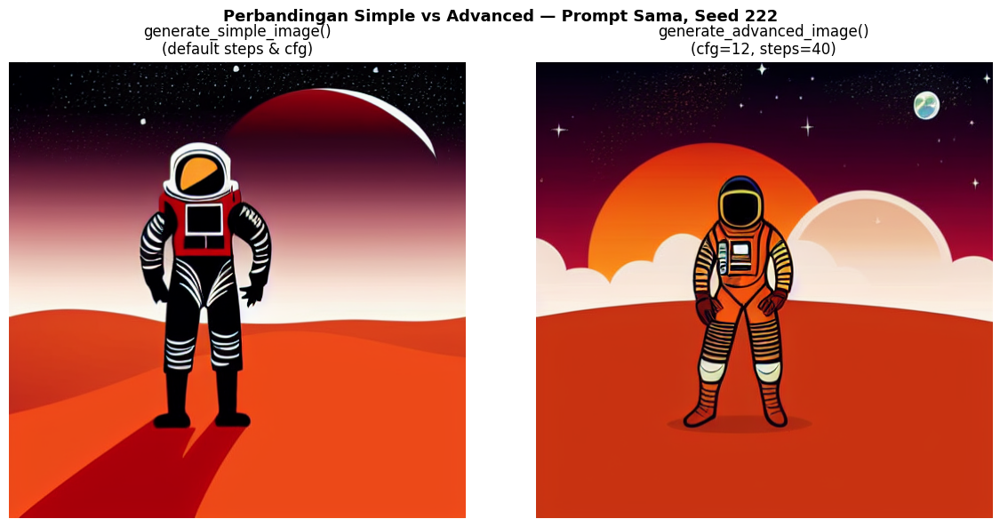

In [24]:
def generate_advanced_image(prompt, negative_prompt, seed, guidance_scale, num_inference_steps):

    generator = torch.Generator(device=DEVICE).manual_seed(seed)

    result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        generator=generator,
        guidance_scale=guidance_scale,
        num_inference_steps=num_inference_steps
    )

    return result.images[0]


# Jalankan generate_advanced_image dengan parameter optimal
advanced_image = generate_advanced_image(
    prompt=PROMPT,
    negative_prompt=NEGATIVE_PROMPT,
    seed=SEED,
    guidance_scale=12.0,
    num_inference_steps=40
)

# Tampilkan perbandingan Simple vs Advanced
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(simple_image)
axes[0].set_title("generate_simple_image()\n(default steps & cfg)", fontsize=12)
axes[0].axis("off")

axes[1].imshow(advanced_image)
axes[1].set_title("generate_advanced_image()\n(cfg=12, steps=40)", fontsize=12)
axes[1].axis("off")

plt.suptitle("Perbandingan Simple vs Advanced — Prompt Sama, Seed 222", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## **Guidance Scale Comparison**

Eksperimen dengan 4 nilai guidance scale berbeda untuk melihat pengaruhnya terhadap kualitas gambar:
- **Scale rendah (3, 5)** — model lebih bebas berkreasi, gambar bisa menyimpang dari prompt
- **Scale tinggi (12, 17)** — model sangat patuh pada prompt, detail lebih tajam tapi bisa over-saturated

Generating guidance_scale=3 ...


  0%|          | 0/30 [00:00<?, ?it/s]

Generating guidance_scale=5 ...


  0%|          | 0/30 [00:00<?, ?it/s]

Generating guidance_scale=12 ...


  0%|          | 0/30 [00:00<?, ?it/s]

Generating guidance_scale=17 ...


  0%|          | 0/30 [00:00<?, ?it/s]

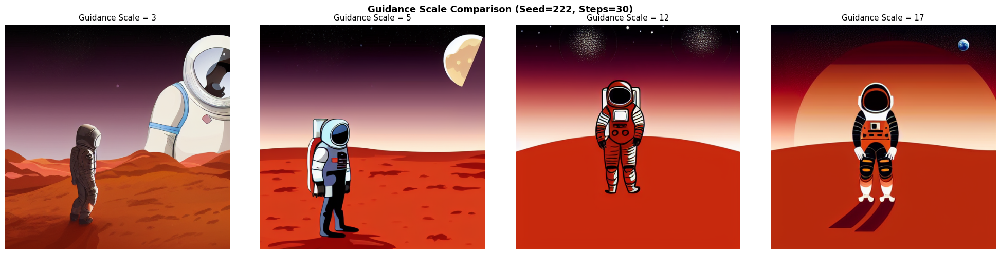

In [25]:
guidance_scales = [3, 5, 12, 17]
gs_images = []

for gs in guidance_scales:
    print(f"Generating guidance_scale={gs} ...")
    img = generate_advanced_image(
        prompt=PROMPT,
        negative_prompt=NEGATIVE_PROMPT,
        seed=SEED,
        guidance_scale=gs,
        num_inference_steps=30
    )
    gs_images.append(img)

# Visualisasi
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, img, gs in zip(axes, gs_images, guidance_scales):
    ax.imshow(img)
    ax.set_title(f"Guidance Scale = {gs}", fontsize=11)
    ax.axis("off")

plt.suptitle("Guidance Scale Comparison (Seed=222, Steps=30)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### **Guidance Scale Explanation:**

*   **Gambar dengan "Scale" Rendah (3–5):**  
Gambar yang dihasilkan cenderung lebih "bebas" dan tidak terlalu terikat pada deskripsi prompt. Detail astronot dan permukaan Mars masih muncul namun komposisi warna dan bentuk kurang konsisten. Variasi visual lebih tinggi — misalnya proporsi astronot bisa aneh atau elemen seperti Bumi di langit tidak muncul dengan jelas. Kesesuaian dengan prompt rendah, tetapi gambar terasa lebih "organik" dan beragam.

*   **Gambar dengan "Scale" Tinggi (12–17):**  
Gambar jauh lebih patuh terhadap prompt. Elemen-elemen kunci seperti astronot, permukaan merah Mars, dan Bumi di latar langit gelap tampil lebih jelas dan proporsional. Detail tekstur tanah dan visual kartun lebih tajam. Namun pada scale sangat tinggi (17+), warna bisa menjadi over-saturated dan gambar terlihat sedikit "dipaksakan" atau kaku secara artistik.

## **Inference Steps Comparison**

Eksperimen dengan jumlah inference steps rendah (5–15) dan tinggi (30–50):
- **Step rendah** — proses cepat, namun gambar masih mengandung noise/artefak
- **Step tinggi** — gambar lebih halus dan detail, proses lebih lama

Generating num_inference_steps=5 ...


  0%|          | 0/5 [00:00<?, ?it/s]

Generating num_inference_steps=10 ...


  0%|          | 0/10 [00:00<?, ?it/s]

Generating num_inference_steps=30 ...


  0%|          | 0/30 [00:00<?, ?it/s]

Generating num_inference_steps=50 ...


  0%|          | 0/50 [00:00<?, ?it/s]

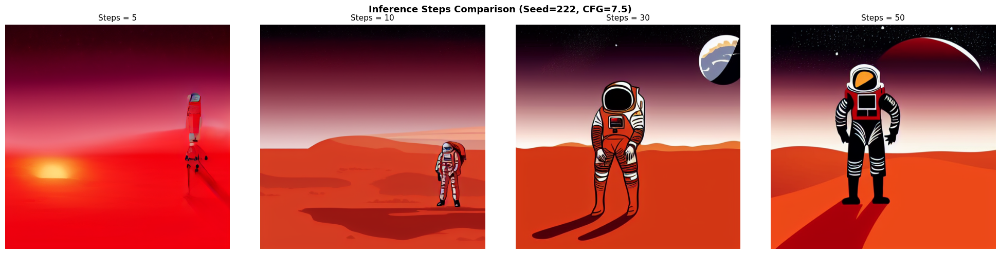

In [26]:
inference_steps_list = [5, 10, 30, 50]
step_images = []

for steps in inference_steps_list:
    print(f"Generating num_inference_steps={steps} ...")
    img = generate_advanced_image(
        prompt=PROMPT,
        negative_prompt=NEGATIVE_PROMPT,
        seed=SEED,
        guidance_scale=7.5,
        num_inference_steps=steps
    )
    step_images.append(img)

# Visualisasi
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, img, steps in zip(axes, step_images, inference_steps_list):
    ax.imshow(img)
    ax.set_title(f"Steps = {steps}", fontsize=11)
    ax.axis("off")

plt.suptitle("Inference Steps Comparison (Seed=222, CFG=7.5)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### **Inference Step Explanation:**

*   **Gambar dengan "Step" Rendah (5–10):**  
Gambar yang dihasilkan terlihat kasar, buram, dan penuh noise/artefak. Bentuk astronot mungkin tidak terbentuk sempurna — proporsi tubuh bisa aneh atau "meleleh". Tekstur tanah Mars dan langit juga kurang terdefinisi dengan baik. Proses denoising yang singkat membuat model tidak punya cukup iterasi untuk membentuk detail yang halus. Gambar terasa seperti sketsa kasar yang belum selesai.

*   **Gambar dengan "Step" Tinggi (30–50):**  
Gambar jauh lebih bersih, tajam, dan detail. Tepi-tepi objek (astronot, horizon Mars) terlihat tegas. Tekstur tanah merah Mars dan detail pada baju astronot terbentuk dengan baik. Langit gelap dengan bintang-bintang kecil juga lebih konsisten. Stabilitas visual meningkat drastis dibanding step rendah — tidak ada noise yang mengganggu dan komposisi gambar secara keseluruhan lebih koheren.

## **Batch Inference from One Prompt**

Menghasilkan 4 gambar sekaligus dari satu prompt menggunakan parameter `num_images_per_prompt=4`.
Hasilnya ditampilkan dalam format **grid 2×2** untuk memudahkan perbandingan variasi output.

  0%|          | 0/30 [00:00<?, ?it/s]

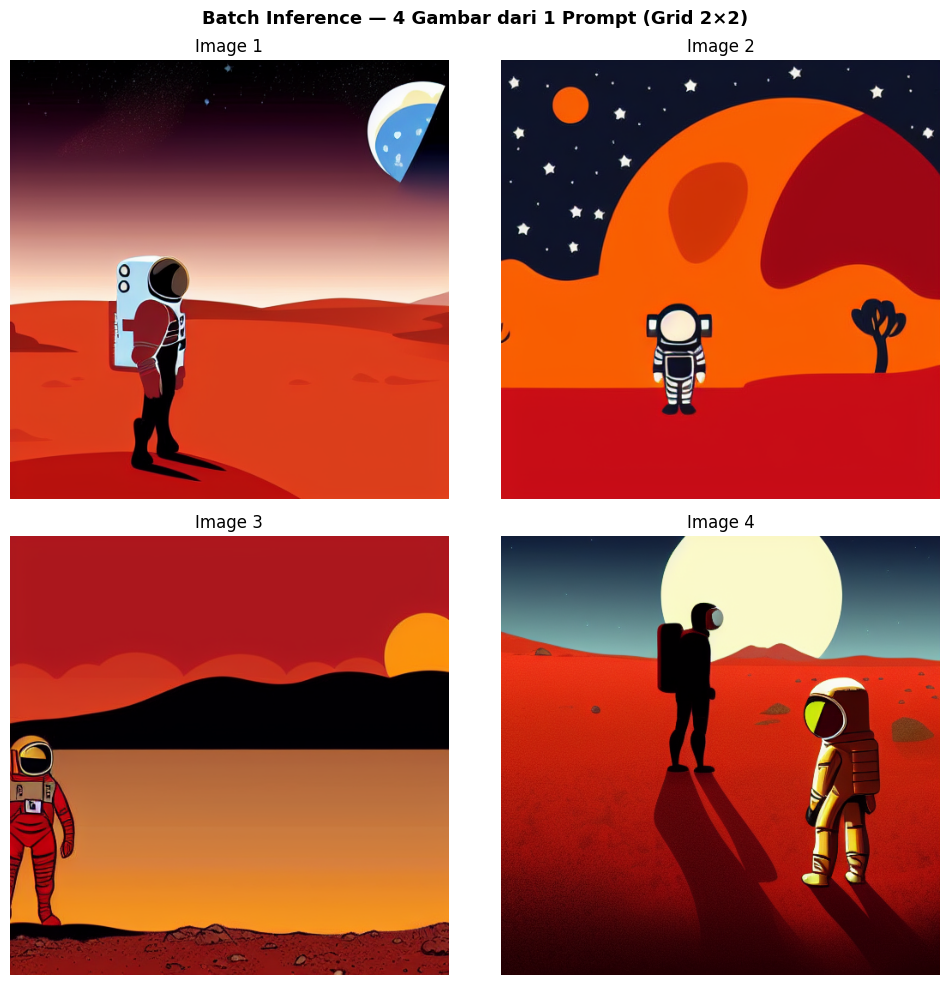

In [27]:
def batch_inference(prompt, negative_prompt, seed, guidance_scale, num_inference_steps, num_images=4):

    generator = torch.Generator(device=DEVICE).manual_seed(seed)

    result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        generator=generator,
        guidance_scale=guidance_scale,
        num_inference_steps=num_inference_steps,
        num_images_per_prompt=num_images
    )

    return result.images


# Generate 4 gambar sekaligus
batch_images = batch_inference(
    prompt=PROMPT,
    negative_prompt=NEGATIVE_PROMPT,
    seed=SEED,
    guidance_scale=7.5,
    num_inference_steps=30,
    num_images=4
)

# Tampilkan dalam grid 2x2
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for idx, (ax, img) in enumerate(zip(axes.flatten(), batch_images)):
    ax.imshow(img)
    ax.set_title(f"Image {idx + 1}", fontsize=12)
    ax.axis("off")

plt.suptitle("Batch Inference — 4 Gambar dari 1 Prompt (Grid 2×2)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## **Load Scheduler**

### Fungsi `load_scheduler()`
Memungkinkan pergantian algoritma sampling (scheduler) **tanpa perlu memuat ulang model**.
Tiga scheduler yang diuji:
- **Euler A (EulerAncestralDiscreteScheduler)** — cepat, menghasilkan gambar kreatif dengan variasi tinggi
- **DPM++ (DPMSolverMultistepScheduler)** — kualitas tinggi dengan step lebih sedikit, sangat efisien
- **DDIM (DDIMScheduler)** — deterministik, hasil lebih konsisten dan terprediksi


--- Scheduler: Euler A ---
Scheduler diubah ke: Euler A (EulerAncestralDiscreteScheduler)


  0%|          | 0/30 [00:00<?, ?it/s]

Done: Euler A

--- Scheduler: DPM++ ---
Scheduler diubah ke: DPM++ (DPMSolverMultistepScheduler)


  0%|          | 0/30 [00:00<?, ?it/s]

Done: DPM++

--- Scheduler: DDIM ---
Scheduler diubah ke: DDIM (DDIMScheduler)


  0%|          | 0/30 [00:00<?, ?it/s]

Done: DDIM


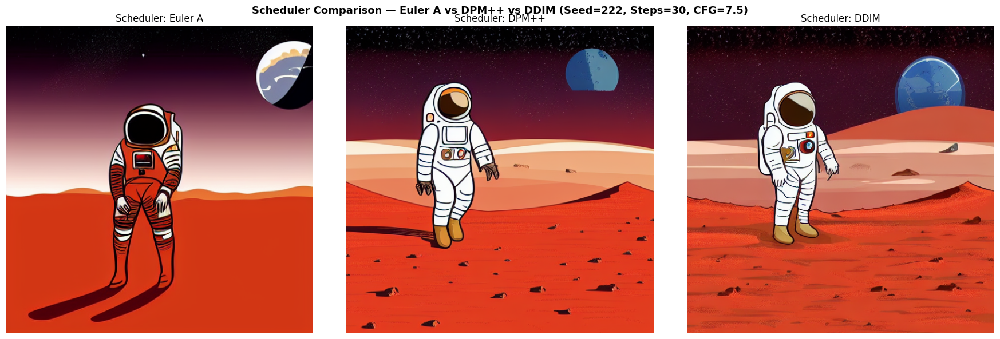

In [28]:
def load_scheduler(pipe, scheduler_name):

    config = pipe.scheduler.config

    if scheduler_name == "Euler A":
        pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(config)
    elif scheduler_name == "DPM++":
        pipe.scheduler = DPMSolverMultistepScheduler.from_config(config)
    elif scheduler_name == "DDIM":
        pipe.scheduler = DDIMScheduler.from_config(config)
    else:
        raise ValueError(f"Scheduler '{scheduler_name}' tidak dikenal. Pilih: 'Euler A', 'DPM++', 'DDIM'.")

    print(f"Scheduler diubah ke: {scheduler_name} ({type(pipe.scheduler).__name__})")
    return pipe


# Eksperimen dengan 3 scheduler berbeda
schedulers = ["Euler A", "DPM++", "DDIM"]
scheduler_images = []

for sched_name in schedulers:
    print(f"\n--- Scheduler: {sched_name} ---")
    pipe = load_scheduler(pipe, sched_name)

    img = generate_advanced_image(
        prompt=PROMPT,
        negative_prompt=NEGATIVE_PROMPT,
        seed=SEED,
        guidance_scale=7.5,
        num_inference_steps=30
    )
    scheduler_images.append(img)
    print(f"Done: {sched_name}")

# Visualisasi perbandingan 3 scheduler
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, img, name in zip(axes, scheduler_images, schedulers):
    ax.imshow(img)
    ax.set_title(f"Scheduler: {name}", fontsize=12)
    ax.axis("off")

plt.suptitle("Scheduler Comparison — Euler A vs DPM++ vs DDIM (Seed=222, Steps=30, CFG=7.5)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### **Scheduler Comparison:**

*   **Gambar dengan "Euler A Scheduler":**  
Euler Ancestral menghasilkan gambar dengan variasi visual yang lebih tinggi dan nuansa warna yang lebih kaya. Karena sifatnya yang stochastic (acak per step), gambar terasa lebih "hidup" dan artistik. Detail astronot dan elemen Mars muncul dengan gaya ilustrasi yang ekspresif. Namun karena sifat acaknya, hasilnya kurang deterministik dibanding DDIM.

*   **Gambar dengan "DPM++ Scheduler":**  
DPM++ Multistep menghasilkan gambar berkualitas tinggi dengan jumlah step yang lebih sedikit secara efektif. Gambar memiliki detail yang tajam dan konsisten — astronot terlihat proporsional dengan tekstur baju yang lebih terdefenisi. Sangat efisien dan merupakan pilihan terbaik untuk keseimbangan kualitas vs kecepatan. Warna dan komposisi paling seimbang di antara ketiga scheduler.

*   **Gambar dengan "DDIM Scheduler":**  
DDIM (Denoising Diffusion Implicit Models) bersifat deterministik — dengan seed yang sama, hasilnya selalu identik. Gambar yang dihasilkan cenderung lebih "bersih" dan teratur namun sedikit kurang kreatif dibanding Euler A. Detail gambar konsisten tapi mungkin terasa lebih "kaku" secara artistik. Cocok untuk kasus di mana reproducibility adalah prioritas utama.

# **Kriteria 2: Menyempurnakan Gambar Melalui Image-to-Image**

## **Base + Refiner Image Generation**

### Two-Stage Generation (Base + Refiner Pattern)
Teknik ini menggunakan dua tahap generasi untuk meningkatkan kualitas gambar:
- **Stage 1 (Base)**: Menghasilkan latent awal dengan `denoising_end=0.8` — hanya 80% proses denoising
- **Stage 2 (Refiner/Img2Img)**: Melanjutkan dari latent tersebut dengan `denoising_start=0.8` — menyempurnakan 20% terakhir

Hasil akhir memiliki kualitas lebih tinggi dibanding single-stage generation.

Scheduler diubah ke: Euler A (EulerAncestralDiscreteScheduler)
Stage 1: Base generation...


  0%|          | 0/40 [00:00<?, ?it/s]

Stage 2: Refiner...


  0%|          | 0/7 [00:00<?, ?it/s]

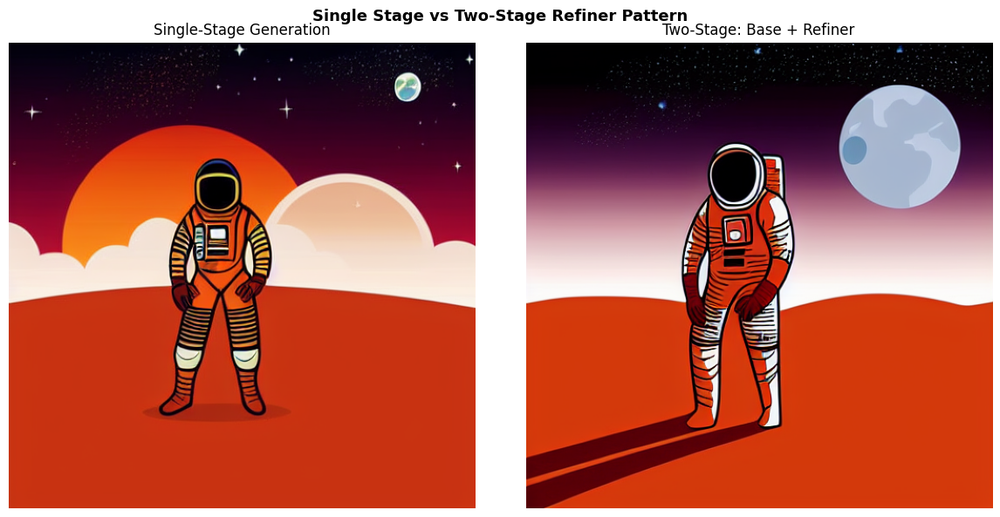

In [29]:
# Reset ke scheduler default (Euler A) sebelum eksperimen ini
pipe = load_scheduler(pipe, "Euler A")

# Load pipeline Img2Img untuk Stage 2 (Refiner)
pipe_img2img = StableDiffusionImg2ImgPipeline(
    vae=pipe.vae,
    text_encoder=pipe.text_encoder,
    tokenizer=pipe.tokenizer,
    unet=pipe.unet,
    scheduler=pipe.scheduler,
    safety_checker=None,
    feature_extractor=None,
    requires_safety_checker=False
).to(DEVICE)


def generate_with_refiner(prompt, negative_prompt, seed, guidance_scale=7.5,
                           num_inference_steps=40, denoising_cutoff=0.8):

    generator = torch.Generator(device=DEVICE).manual_seed(seed)

    # Stage 1 — Base generation, hasilkan gambar awal (80% denoising)
    print("Stage 1: Base generation...")
    base_result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        generator=generator,
        guidance_scale=guidance_scale,
        num_inference_steps=num_inference_steps,
        denoising_end=denoising_cutoff,
        output_type="latent"  # keluarkan latent, bukan gambar langsung
    )
    latent_image = base_result.images

    # Stage 2 — Refiner: lanjutkan dari latent Stage 1 (20% terakhir)
    print("Stage 2: Refiner...")
    generator2 = torch.Generator(device=DEVICE).manual_seed(seed)
    refined_result = pipe_img2img(
        prompt=prompt,
        negative_prompt=negative_prompt,
        image=latent_image,
        generator=generator2,
        guidance_scale=guidance_scale,
        num_inference_steps=num_inference_steps,
        strength=1 - denoising_cutoff  # strength = sisa denoising (20%)
    )

    return refined_result.images[0]


refined_image = generate_with_refiner(
    prompt=PROMPT,
    negative_prompt=NEGATIVE_PROMPT,
    seed=SEED,
    guidance_scale=7.5,
    num_inference_steps=40
)

# Simpan gambar ini sebagai base untuk inpainting
base_image_for_inpaint = refined_image.copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(advanced_image)
axes[0].set_title("Single-Stage Generation", fontsize=12)
axes[0].axis("off")
axes[1].imshow(refined_image)
axes[1].set_title("Two-Stage: Base + Refiner", fontsize=12)
axes[1].axis("off")
plt.suptitle("Single Stage vs Two-Stage Refiner Pattern", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## **Inpainting**

Inpainting adalah teknik memodifikasi area tertentu dalam gambar menggunakan mask.
- Area **putih** pada mask = area yang akan di-regenerasi oleh model
- Area **hitam** pada mask = area yang dipertahankan (tidak diubah)

### **Load Model Inpainting**

Model inpainting yang digunakan adalah `runwayml/stable-diffusion-inpainting` — model khusus yang dilatih untuk task inpainting, berbeda dari model text-to-image biasa.

In [30]:
INPAINT_MODEL_ID = "runwayml/stable-diffusion-inpainting"

pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(
    INPAINT_MODEL_ID,
    torch_dtype=torch.float16,
    safety_checker=None,
    requires_safety_checker=False
).to(DEVICE)

pipe_inpaint.enable_attention_slicing()
print("Inpainting model berhasil di-load!")


def inpaint_engine(image, mask, prompt, seed=9, guidance_scale=7.5, num_inference_steps=30):

    # Pastikan format gambar dan mask benar
    image = image.convert("RGB")
    mask = mask.convert("L")

    # Resize ke 512x512 (ukuran standar SD v1.5)
    image = image.resize((512, 512), Image.LANCZOS)
    mask = mask.resize((512, 512), Image.NEAREST)

    generator = torch.Generator(device=DEVICE).manual_seed(seed)

    result = pipe_inpaint(
        prompt=prompt,
        image=image,
        mask_image=mask,
        generator=generator,
        guidance_scale=guidance_scale,
        num_inference_steps=num_inference_steps
    )

    return result.images[0]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Inpainting model berhasil di-load!


### **Manual Masking**

Masking dilakukan secara manual (hardcode) dengan menentukan koordinat area yang akan di-edit.
Berdasarkan target gambar dari brief, area mask ditempatkan di sisi kanan bawah — lokasi di mana *broken satellite* akan ditempatkan.

Pendekatan: **trial and error** untuk menemukan koordinat mask yang tepat.

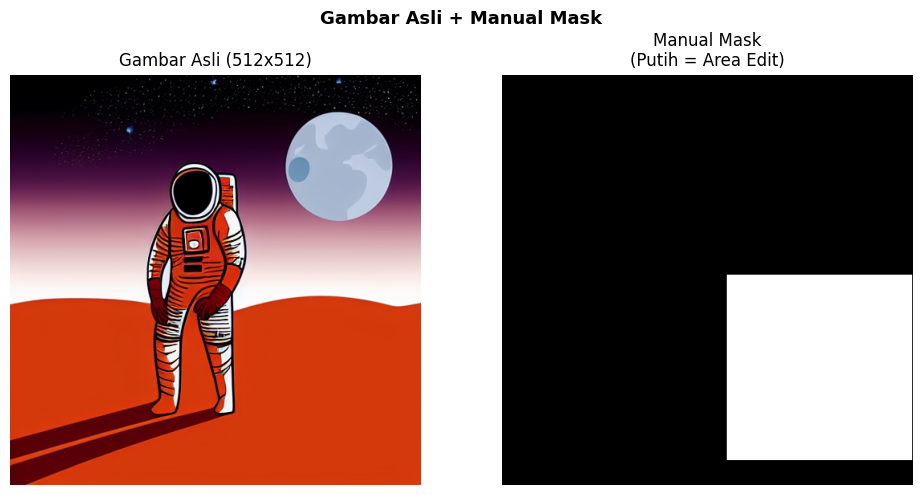

In [31]:
# Resize base image ke 512x512 terlebih dahulu
base_img_512 = base_image_for_inpaint.resize((512, 512), Image.LANCZOS)

def create_manual_mask(width=512, height=512, mask_region=None):

    mask = Image.new("L", (width, height), 0)  # hitam = pertahankan
    draw = ImageDraw.Draw(mask)

    if mask_region:
        draw.rectangle(mask_region, fill=255)  # putih = edit

    return mask

# Koordinat mask: area kanan-tengah untuk menempatkan broken satellite
# Trial and error: area (280, 250, 510, 480) mencakup sisi kanan gambar
MASK_REGION = (280, 250, 510, 480)

manual_mask = create_manual_mask(512, 512, mask_region=MASK_REGION)

# Visualisasi gambar + mask
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(base_img_512)
axes[0].set_title("Gambar Asli (512x512)", fontsize=12)
axes[0].axis("off")

axes[1].imshow(manual_mask, cmap="gray")
axes[1].set_title("Manual Mask\n(Putih = Area Edit)", fontsize=12)
axes[1].axis("off")

plt.suptitle("Gambar Asli + Manual Mask", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### **Generate (Manual Masking Inpainting)**

Menggunakan `inpaint_engine()` dengan mask manual untuk menambahkan *broken satellite* di area kanan gambar.
Seed bernilai **9** sesuai ketentuan brief.

  0%|          | 0/40 [00:00<?, ?it/s]

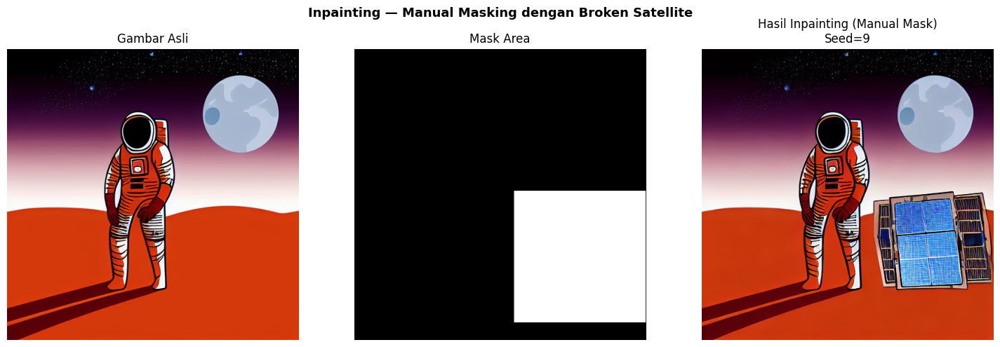

In [32]:
INPAINT_PROMPT = (
    "a broken damaged satellite crashed on Mars surface, "
    "metallic debris, solar panels bent and shattered, "
    "realistic, detailed, science fiction"
)

inpainted_manual = inpaint_engine(
    image=base_img_512,
    mask=manual_mask,
    prompt=INPAINT_PROMPT,
    seed=9,
    guidance_scale=9.0,
    num_inference_steps=40
)

# Visualisasi hasil inpainting manual
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(base_img_512)
axes[0].set_title("Gambar Asli", fontsize=12)
axes[0].axis("off")

axes[1].imshow(manual_mask, cmap="gray")
axes[1].set_title("Mask Area", fontsize=12)
axes[1].axis("off")

axes[2].imshow(inpainted_manual)
axes[2].set_title("Hasil Inpainting (Manual Mask)\nSeed=9", fontsize=12)
axes[2].axis("off")

plt.suptitle("Inpainting — Manual Masking dengan Broken Satellite", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# Simpan sebagai base untuk outpainting
inpainted_result = inpainted_manual.copy()

## **Inpainting Menggunakan Automasking**

Pada bagian ini, masking dilakukan secara **otomatis** menggunakan model segmentation.
Model segmentation mendeteksi objek dalam gambar, kemudian area objek tertentu dijadikan mask secara otomatis — tanpa hardcode koordinat.

### **Load Model Segmentation untuk Masking**

Menggunakan `facebook/mask2former-swin-base-coco-panoptic` dari HuggingFace Transformers
sebagai model segmentation untuk mendeteksi dan mensegmentasi objek dalam gambar secara otomatis.

In [33]:
from transformers import pipeline as hf_pipeline

# Load model segmentation (panoptic segmentation)
segmenter = hf_pipeline(
    "image-segmentation",
    model="facebook/mask2former-swin-base-coco-panoptic",
    device=0 if torch.cuda.is_available() else -1
)

print("Segmentation model berhasil di-load!")

Loading weights:   0%|          | 0/782 [00:00<?, ?it/s]

Segmentation model berhasil di-load!


### **Masking with Segmentation Model**

Model segmentation akan mendeteksi semua objek dalam gambar.
Kita pilih objek dengan label `person` (astronot) untuk dijadikan mask.
Area mask ini kemudian dibalik (invert) agar area DI LUAR astronot yang akan diedit — berguna untuk menambahkan elemen baru di background.

`label_ids_to_fuse` unset. No instance will be fused.
/tmp/ipykernel_4160/2873483951.py:32: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask_pil = Image.fromarray(mask_array, mode='L')
/tmp/ipykernel_4160/2873483951.py:54: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  combined_auto_mask = Image.fromarray(combined_mask_arr.astype(np.uint8), mode='L')


Label terdeteksi: []
Label 'person' tidak ditemukan. Gunakan mask kosong.


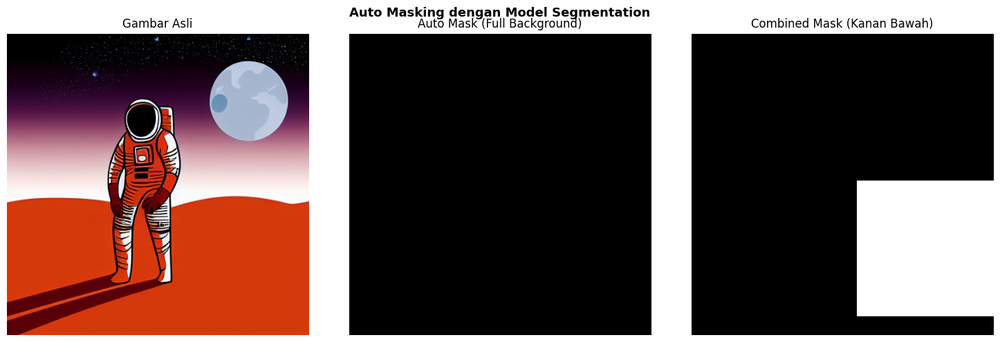

In [34]:
import numpy as np
from PIL import Image

def generate_auto_mask(image, segmenter, target_label="person", invert=False):

    results = segmenter(image)

    # Tampilkan semua label yang terdeteksi
    detected_labels = [r['label'] for r in results]
    print(f"Label terdeteksi: {detected_labels}")

    # Cari segmentasi yang sesuai target_label
    target_mask = None
    for seg in results:
        if target_label.lower() in seg['label'].lower():
            target_mask = np.array(seg['mask'])
            print(f"Mask ditemukan untuk label: {seg['label']}")
            break

    if target_mask is None:
        # Jika target tidak ditemukan, fallback ke mask seluruh gambar
        print(f"Label '{target_label}' tidak ditemukan. Gunakan mask kosong.")
        target_mask = np.zeros((image.size[1], image.size[0]), dtype=np.uint8)

    # Konversi ke 0-255
    mask_array = (target_mask * 255).astype(np.uint8)

    # Invert jika diminta (edit area di luar objek)
    if invert:
        mask_array = 255 - mask_array

    mask_pil = Image.fromarray(mask_array, mode='L')
    mask_pil = mask_pil.resize(image.size, Image.NEAREST)

    return mask_pil


# Buat auto mask pada gambar astronot
# Kita pakai invert=True → area DI LUAR astronot (background) yang akan di-edit
# lalu kita batasi hanya area kanan bawah dengan logical AND
auto_mask = generate_auto_mask(
    image=base_img_512,
    segmenter=segmenter,
    target_label="person",
    invert=True   # edit area background, bukan astronotnya
)

# Batasi area auto-mask ke kanan bawah saja (agar fokus ke area satellite)
# dengan mengalikan dengan manual mask region
auto_mask_arr = np.array(auto_mask)
region_filter = np.zeros_like(auto_mask_arr)
region_filter[250:480, 280:512] = 255  # area kanan bawah
combined_mask_arr = np.minimum(auto_mask_arr, region_filter)
combined_auto_mask = Image.fromarray(combined_mask_arr.astype(np.uint8), mode='L')

# Visualisasi
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(base_img_512)
axes[0].set_title("Gambar Asli", fontsize=12)
axes[0].axis("off")

axes[1].imshow(auto_mask, cmap="gray")
axes[1].set_title("Auto Mask (Full Background)", fontsize=12)
axes[1].axis("off")

axes[2].imshow(combined_auto_mask, cmap="gray")
axes[2].set_title("Combined Mask (Kanan Bawah)", fontsize=12)
axes[2].axis("off")

plt.suptitle("Auto Masking dengan Model Segmentation", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### **Generate (Auto Masking Inpainting)**

Gunakan mask otomatis dari segmentation model untuk menjalankan inpainting.

  0%|          | 0/40 [00:00<?, ?it/s]

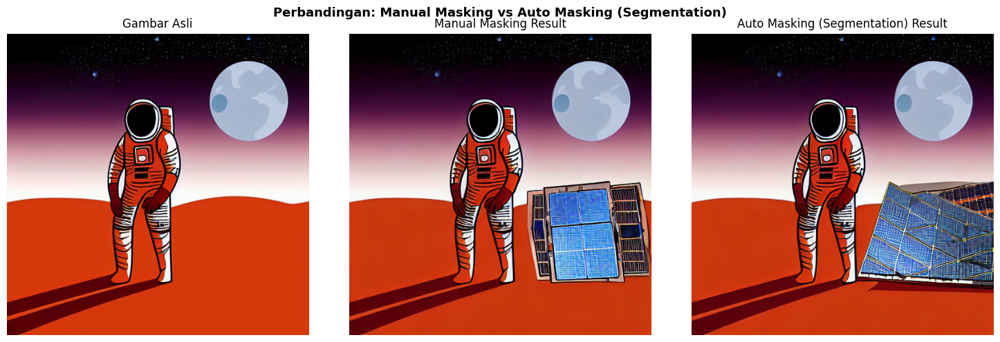

In [35]:
inpainted_auto = inpaint_engine(
    image=base_img_512,
    mask=combined_auto_mask,
    prompt=INPAINT_PROMPT,
    seed=9,
    guidance_scale=9.0,
    num_inference_steps=40
)

# Visualisasi perbandingan manual vs auto masking
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(base_img_512)
axes[0].set_title("Gambar Asli", fontsize=12)
axes[0].axis("off")

axes[1].imshow(inpainted_manual)
axes[1].set_title("Manual Masking Result", fontsize=12)
axes[1].axis("off")

axes[2].imshow(inpainted_auto)
axes[2].set_title("Auto Masking (Segmentation) Result", fontsize=12)
axes[2].axis("off")

plt.suptitle("Perbandingan: Manual Masking vs Auto Masking (Segmentation)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## **Outpainting**

Outpainting adalah teknik memperluas kanvas gambar ke satu arah tertentu.

### Fungsi `prepare_outpainting()`
- Memperluas kanvas gambar dengan menambahkan padding di satu sisi (kiri/kanan/atas/bawah)
- Area baru (padding) diberi mask putih agar model mengisinya
- Area gambar asli diberi mask hitam agar tidak diubah

### **Prepare the Canvas**

Menyiapkan kanvas dengan padding di satu sisi menggunakan gambar hasil inpainting sebagai input.

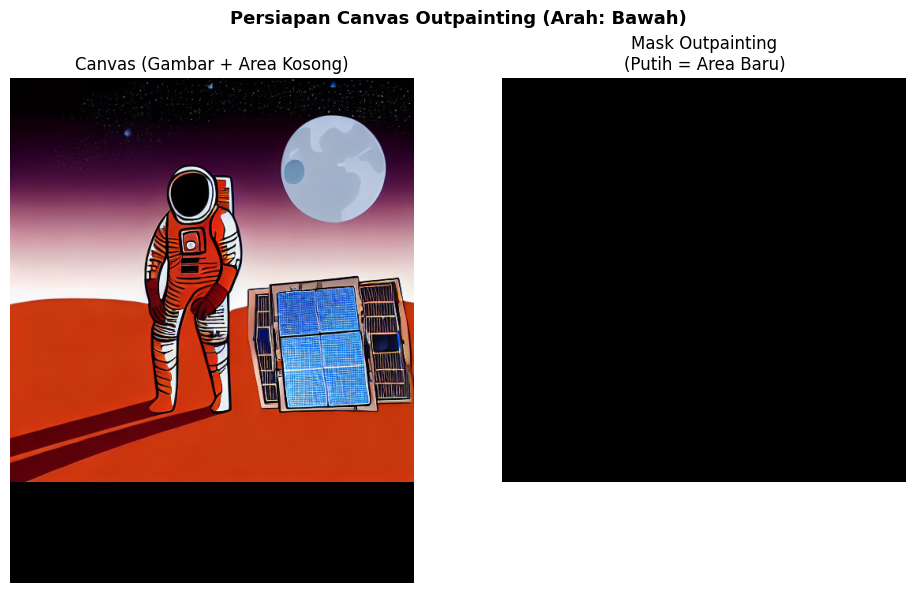

In [36]:
def prepare_outpainting(image, direction="right", expand_pixels=128):

    w, h = image.size

    if direction in ["left", "right"]:
        new_w = w + expand_pixels
        new_h = h
    else:  # top, bottom
        new_w = w
        new_h = h + expand_pixels

    # Pastikan kelipatan 8 (requirement SD)
    new_w = new_w - (new_w % 8)
    new_h = new_h - (new_h % 8)

    # Buat kanvas kosong (hitam) dan tempel gambar asli
    canvas = Image.new("RGB", (new_w, new_h), (0, 0, 0))

    if direction == "right":
        paste_x, paste_y = 0, 0
    elif direction == "left":
        paste_x, paste_y = expand_pixels, 0
    elif direction == "bottom":
        paste_x, paste_y = 0, 0
    else:  # top
        paste_x, paste_y = 0, expand_pixels

    canvas.paste(image, (paste_x, paste_y))

    # Buat mask: putih = area baru (kosong), hitam = gambar asli
    mask = Image.new("L", (new_w, new_h), 255)  # semua putih dulu
    inner = Image.new("L", (w, h), 0)            # hitam = gambar asli
    mask.paste(inner, (paste_x, paste_y))

    return canvas, mask


# Siapkan kanvas outpainting ke arah BAWAH
canvas_out, mask_out = prepare_outpainting(
    image=inpainted_result,
    direction="bottom",
    expand_pixels=128
)

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].imshow(canvas_out)
axes[0].set_title("Canvas (Gambar + Area Kosong)", fontsize=12)
axes[0].axis("off")

axes[1].imshow(mask_out, cmap="gray")
axes[1].set_title("Mask Outpainting\n(Putih = Area Baru)", fontsize=12)
axes[1].axis("off")

plt.suptitle("Persiapan Canvas Outpainting (Arah: Bawah)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### **Generate (Outpainting)**

Jalankan inpainting pada kanvas yang sudah disiapkan untuk mengisi area baru dengan konten yang konsisten dengan gambar asli.

  0%|          | 0/40 [00:00<?, ?it/s]

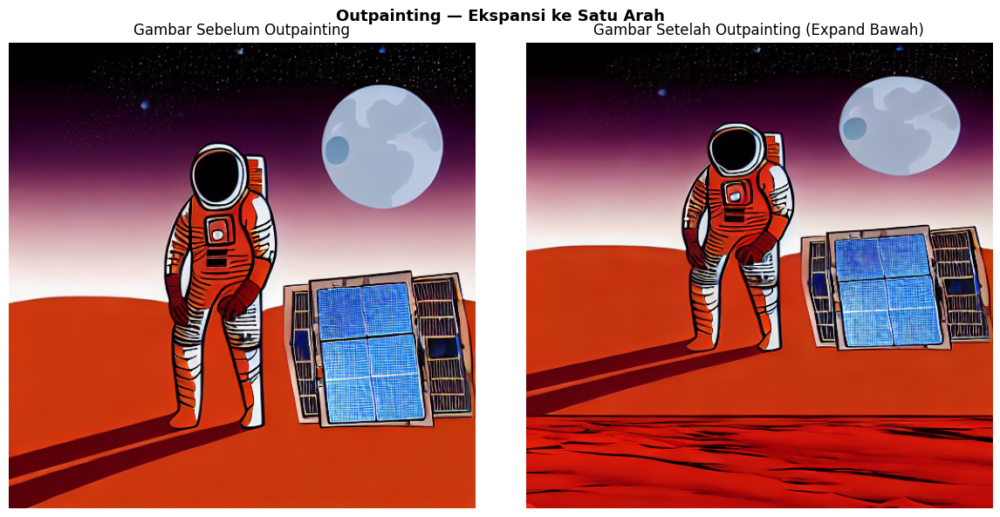

In [49]:
OUTPAINT_PROMPT = (
     "wide expansive view of the desolate red martian surface, towering rocky canyons in the distance, deep black starry space, glowing atmosphere, photorealistic"
)

outpainted_image = inpaint_engine(
    image=canvas_out,
    mask=mask_out,
    prompt=OUTPAINT_PROMPT,
    seed=42,
    guidance_scale=8.0,
    num_inference_steps=40
)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(inpainted_result)
axes[0].set_title("Gambar Sebelum Outpainting", fontsize=12)
axes[0].axis("off")

axes[1].imshow(outpainted_image)
axes[1].set_title("Gambar Setelah Outpainting (Expand Bawah)", fontsize=12)
axes[1].axis("off")

plt.suptitle("Outpainting — Ekspansi ke Satu Arah", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## **Outpainting Zoom Out**

Teknik Zoom Out memperluas gambar secara bertahap ke **semua arah sekaligus** (kiri, kanan, atas, bawah).
Prosesnya bisa dilakukan berulang (iteratif) untuk semakin memperluas sudut pandang gambar.

### **Prepare Canvas for Zoom Out**

Berbeda dengan outpainting satu arah, Zoom Out menambahkan padding di semua sisi sekaligus.
Gambar asli di-resize dan ditempatkan di tengah kanvas yang lebih besar.

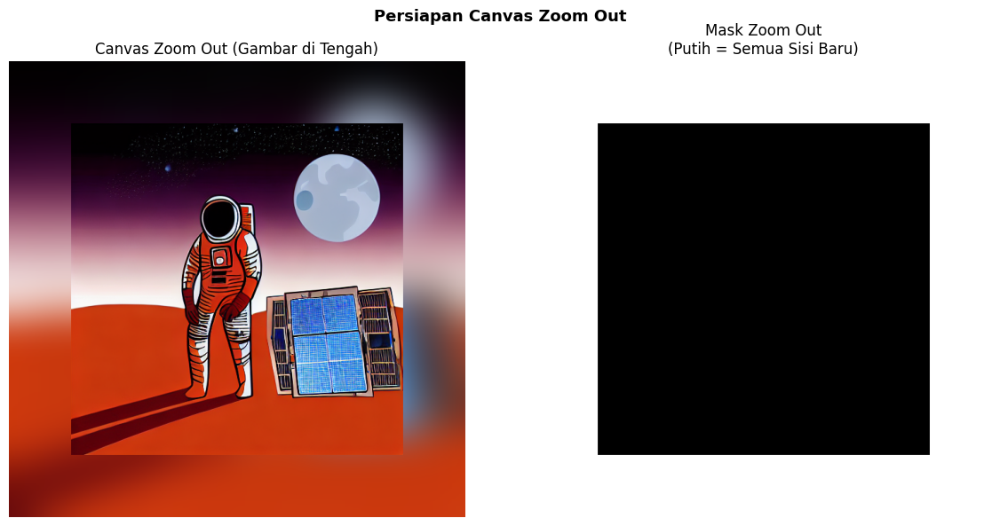

In [50]:
def prepare_zoom_out(image, expand_pixels=128):

    w, h = image.size

    new_w = w + 2 * expand_pixels
    new_h = h + 2 * expand_pixels

    # Pastikan kelipatan 8
    new_w = new_w - (new_w % 8)
    new_h = new_h - (new_h % 8)

    # Blur background dari gambar asli yang di-resize sebagai filler
    from PIL import ImageFilter
    bg = image.resize((new_w, new_h), Image.BICUBIC)
    bg = bg.filter(ImageFilter.GaussianBlur(radius=30))

    # Tempel gambar asli di tengah
    canvas = bg.copy()
    paste_x = (new_w - w) // 2
    paste_y = (new_h - h) // 2
    canvas.paste(image, (paste_x, paste_y))

    # Mask: putih di area border (baru), hitam di tengah (gambar asli)
    mask = Image.new("L", (new_w, new_h), 255)   # semua putih
    inner_box = Image.new("L", (w, h), 0)         # hitam = area asli
    mask.paste(inner_box, (paste_x, paste_y))

    return canvas, mask


def iterative_zoom_out(image, prompt, num_iterations=2, expand_pixels=96,
                        seed=9, guidance_scale=8.0, num_inference_steps=30):

    current_img = image.copy()
    results = [current_img]

    for i in range(num_iterations):
        print(f"Zoom Out Iterasi {i+1}/{num_iterations}...")
        canvas, mask = prepare_zoom_out(current_img, expand_pixels=expand_pixels)
        current_img = inpaint_engine(
            image=canvas,
            mask=mask,
            prompt=prompt,
            seed=seed + i,
            guidance_scale=guidance_scale,
            num_inference_steps=num_inference_steps
        )
        results.append(current_img)

    return results


# Preview canvas zoom out sebelum generate
canvas_zo, mask_zo = prepare_zoom_out(inpainted_result, expand_pixels=96)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(canvas_zo)
axes[0].set_title("Canvas Zoom Out (Gambar di Tengah)", fontsize=12)
axes[0].axis("off")

axes[1].imshow(mask_zo, cmap="gray")
axes[1].set_title("Mask Zoom Out\n(Putih = Semua Sisi Baru)", fontsize=12)
axes[1].axis("off")

plt.suptitle("Persiapan Canvas Zoom Out", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### **Generate (Zoom Out Iteratif)**

Jalankan proses Zoom Out secara iteratif. Setiap iterasi memperluas sudut pandang gambar ke segala arah.

Melakukan Zoom Out... Membangun dunia di sekitar karakter!


  0%|          | 0/30 [00:00<?, ?it/s]

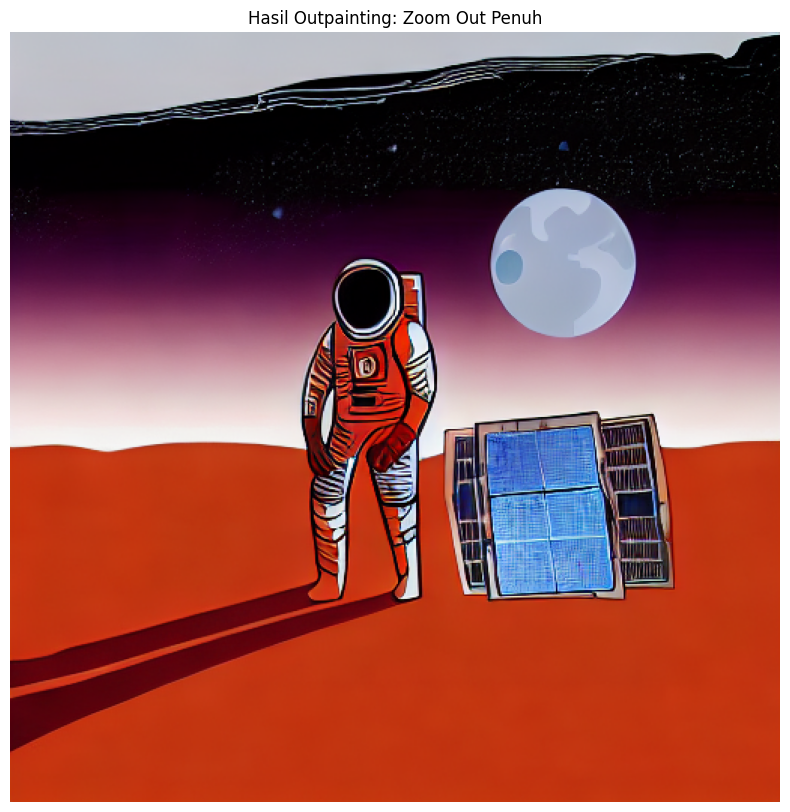

In [56]:
prompt_zoom = "wide expansive view of the desolate red martian surface, towering rocky canyons in the distance, deep black starry space, glowing atmosphere, photorealistic, cinematic lighting, 8k resolution, sci-fi masterpiece"

print("Melakukan Zoom Out... Membangun dunia di sekitar karakter!")

hasil_zoom = inpaint_engine(
    image=canvas_zo,
    mask=mask_zo,
    prompt=prompt_zoom,
    # width dan height tidak perlu di specify jika image dan mask sudah PIL Image
    seed=88
)

plt.figure(figsize=(10, 10))
plt.imshow(hasil_zoom)
plt.title("Hasil Outpainting: Zoom Out Penuh")
plt.axis('off')
plt.show()